# Week 2 — Does calibration language change perplexity under low-rank K/V compression?

Week 1b found, in energy terms: keys transfer across languages, values do not (worst in late
layers), and a projection shared across heads transfers better than per-head projections.
Two things were missing: a **noise floor** and a **quality** measurement. This notebook adds both.

**Design**

1. **Held-out splits, built in.** Every language is split by Wikipedia article id:
   even ids → *calibration*, odd ids → *evaluation*. Bases are always fitted on calibration
   text and tested on evaluation text, including for the matched language. So
   "English basis on English text" is itself an out-of-sample number: that is the noise floor.
2. **Oracle.** A basis fitted on the evaluation text itself (in-sample). It is the best any
   basis of that rank can do on that text, and it bounds the gap from above.
3. **Intervention.** A forward hook replaces the `v_proj` (or `k_proj`) output by its projection
   onto the top-`r` eigenvectors of the calibration Gram, per KV head or shared across the layer.
   This is the data-driven low-rank approximation that weight-factorisation methods such as
   Palu approximate. Rank budgets match: per-head `r = f·head_dim`, shared `r = f·kv_width`.
4. **Paired statistics.** Every configuration runs on the *same* evaluation windows, so
   differences are measured per window and given a bootstrap 95% CI.

**Kaggle settings.** GPU T4 ×1, Internet On. Run once with `SMOKE_TEST = True` on CPU first.
Expected full runtime on one T4: roughly 1 hour with the default grid (`QUICK = True` cuts it
to about 20 minutes).

In [1]:
import os
SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"
QUICK = False                      # smaller grid: shared + per-head at r=0.25 only, late layers only

MODEL_ID = "Qwen/Qwen3-1.7B"
LANGS = ["en", "es", "fi", "qu"]
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000          # per language, for the bases
EVAL_TOKENS = 60_000            # per language, for perplexity and the held-out Gram
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5                  # accept a language if at least this fraction of the budget is found
CALIB_BATCH = 8
EVAL_BATCH = 4                  # per-window losses need full logits; keep small on a T4
SKIP_FIRST_TOKENS = 1
SEED = 0

RANK_FRACS = (0.125, 0.25)
SCOPES = ("head", "joint")
LATE_FROM = 0.75                # "late" layers = last quarter (21–27 for a 28-layer model)
N_BOOT = 2000

OUT_DIR = "/kaggle/working/kv_rank_week2" if os.path.isdir("/kaggle/working") else "./kv_rank_week2"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    SEQ_LEN, CALIB_TOKENS, EVAL_TOKENS, CALIB_BATCH, EVAL_BATCH, N_BOOT = 64, 64 * 24, 64 * 12, 8, 4, 200
print("SMOKE_TEST =", SMOKE_TEST, "| QUICK =", QUICK, "| output ->", OUT_DIR)

SMOKE_TEST = False | QUICK = False | output -> /kaggle/working/kv_rank_week2


In [2]:
import itertools, json, math, time, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED); np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. Model

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    model = LlamaForCausalLM(LlamaConfig(vocab_size=1000, hidden_size=64, intermediate_size=128,
                                         num_hidden_layers=4, num_attention_heads=4,
                                         num_key_value_heads=2, max_position_embeddings=256))
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)
model.to(device).eval()

cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM
LATE = list(range(int(round(LATE_FROM * N_LAYERS)), N_LAYERS))
LAYER_SETS = {"late": LATE} if QUICK else {"all": list(range(N_LAYERS)), "late": LATE}

PROJ = {"K": [], "V": []}
for name, mod in model.named_modules():
    if name.endswith("self_attn.k_proj"): PROJ["K"].append(mod)
    if name.endswith("self_attn.v_proj"): PROJ["V"].append(mod)
assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS
print(f"layers={N_LAYERS} kv_heads={N_KV} head_dim={HEAD_DIM} late={LATE[0]}–{LATE[-1]}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

layers=28 kv_heads=8 head_dim=128 late=21–27


## 2. Data: calibration and evaluation splits by article id

One stream per language. Even article ids fill the calibration set, odd ids the evaluation set,
so the two never share an article.

In [4]:
def wiki_splits(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = {"calib": CALIB_TOKENS // SEQ_LEN, "eval": EVAL_TOKENS // SEQ_LEN}
    win = {"calib": [], "eval": []}
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        split = "calib" if zlib.crc32(str(row["id"]).encode()) % 2 == 0 else "eval"
        if len(win[split]) >= need[split]:
            if all(len(win[s]) >= need[s] for s in win):
                break
            continue
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            if len(win[split]) < need[split]:
                win[split].append(ids[i:i + SEQ_LEN])
    for s in win:
        got = len(win[s])
        if got < MIN_FILL * need[s]:
            raise RuntimeError(f"{lang}/{s}: only {got}/{need[s]} windows; lower the token budget")
        if got < need[s]:
            print(f"  warning: {lang}/{s} has {got}/{need[s]} windows")
    return {s: torch.tensor(w) for s, w in win.items()}


def smoke_splits(lang):
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    mk = lambda n: torch.randint(lo, lo + 300, (n // SEQ_LEN, SEQ_LEN), generator=g)
    return {"calib": mk(CALIB_TOKENS), "eval": mk(EVAL_TOKENS)}


data = {}
for lang in LANGS:
    t0 = time.time()
    data[lang] = (smoke_splits if SMOKE_TEST else wiki_splits)(lang)
    print(f"{lang}: calib {tuple(data[lang]['calib'].shape)}  eval {tuple(data[lang]['eval'].shape)}  ({time.time()-t0:.0f}s)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

en: calib (292, 512)  eval (117, 512)  (7s)
es: calib (292, 512)  eval (117, 512)  (5s)
fi: calib (292, 512)  eval (117, 512)  (4s)
qu: calib (292, 512)  eval (117, 512)  (4s)


## 3. Gram matrices and baseline perplexity

- Calibration Gram (for the bases) from the calibration split.
- Evaluation Gram (for the oracle and the energy noise floor) from the evaluation split,
  collected in the same pass that measures the uncompressed per-window loss.

In [5]:
class GramCollector:
    def __init__(self):
        self.gram = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
        self.n = 0
        self.handles = [m.register_forward_hook(self._hook(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]

    def _hook(self, kind, layer):
        def fn(mod, inp, out):
            x = out[:, SKIP_FIRST_TOKENS:, :].reshape(-1, out.shape[-1]).float()
            self.gram[kind][layer] += (x.T @ x).double()
            if kind == "K" and layer == 0:
                self.n += x.shape[0]
        return fn

    def result(self):
        for h in self.handles: h.remove()
        return {k: (g / self.n).cpu().numpy() for k, g in self.gram.items()}


@torch.no_grad()
def window_nll(windows, batch):
    # mean next-token NLL per window, shape (n_windows,)
    out = []
    for i in range(0, len(windows), batch):
        ids = windows[i:i + batch].to(device)
        logits = model(input_ids=ids, use_cache=False).logits[:, :-1].float()
        nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), ids[:, 1:].reshape(-1), reduction="none")
        out.append(nll.view(ids.shape[0], -1).mean(1).cpu())
        del logits, nll
    return torch.cat(out).numpy().astype(np.float64)


@torch.no_grad()
def forward_only(windows, batch):
    for i in range(0, len(windows), batch):
        model(input_ids=windows[i:i + batch].to(device), use_cache=False)


gram_calib, gram_eval, base_nll = {}, {}, {}
for lang in LANGS:
    t0 = time.time()
    c = GramCollector(); forward_only(data[lang]["calib"], CALIB_BATCH); gram_calib[lang] = c.result()
    c = GramCollector(); base_nll[lang] = window_nll(data[lang]["eval"], EVAL_BATCH); gram_eval[lang] = c.result()
    if device == "cuda": torch.cuda.empty_cache()
    print(f"{lang}: baseline ppl {math.exp(base_nll[lang].mean()):.2f}  ({time.time()-t0:.0f}s)")

en: baseline ppl 16.39  (65s)
es: baseline ppl 12.53  (66s)
fi: baseline ppl 15.89  (66s)
qu: baseline ppl 35.53  (66s)


## 4. Energy noise floor (CPU, fast)

Efficiency of each calibration basis on each language's **evaluation** Gram, relative to the
oracle basis fitted on that same evaluation Gram. The diagonal (e.g. `en → en`) is the noise floor:
how much a basis loses just from seeing different text in the same language.

In [6]:
def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]

def blocks(G):
    return [G[h*HEAD_DIM:(h+1)*HEAD_DIM, h*HEAD_DIM:(h+1)*HEAD_DIM] for h in range(N_KV)]

def captured(U, G):
    return float(np.einsum("ij,ik,kj->", U, G, U))      # tr(U^T G U)

rows = []
for kind, f, layer in itertools.product(("K", "V"), RANK_FRACS, range(N_LAYERS)):
    for tgt in LANGS:
        Ge = gram_eval[tgt][kind][layer]
        for scope in SCOPES:
            if scope == "head":
                r = max(1, round(f * HEAD_DIM))
                oracle = sum(captured(top_basis(B, r), B) for B in blocks(Ge))
            else:
                r = max(1, round(f * D_KV))
                oracle = captured(top_basis(Ge, r), Ge)
            for src in LANGS:
                Gc = gram_calib[src][kind][layer]
                if scope == "head":
                    got = sum(captured(top_basis(Bc, r), Be) for Bc, Be in zip(blocks(Gc), blocks(Ge)))
                else:
                    got = captured(top_basis(Gc, r), Ge)
                rows.append({"kind": kind, "rank_frac": f, "layer": layer, "scope": scope,
                             "source": src, "target": tgt, "efficiency": got / oracle})
energy = pd.DataFrame(rows)
energy["band"] = np.where(energy.layer.isin(LATE), "late", "other")
energy.to_csv(os.path.join(OUT_DIR, "energy_heldout.csv"), index=False)

for kind in ("K", "V"):
    t = (energy[(energy.kind == kind) & (energy.rank_frac == 0.25) & (energy.band == "late")]
         .groupby(["scope", "source", "target"]).efficiency.mean().unstack().round(3))
    print(f"\n{kind}, late layers, r = 0.25: held-out efficiency (diagonal = noise floor)")
    display(t)


K, late layers, r = 0.25: held-out efficiency (diagonal = noise floor)


target           en     es     fi     qu
scope source                            
head  en      0.998  0.964  0.908  0.953
      es      0.971  0.998  0.923  0.956
      fi      0.938  0.939  0.998  0.950
      qu      0.953  0.960  0.925  0.996
joint en      0.996  0.971  0.933  0.971
      es      0.980  0.997  0.938  0.975
      fi      0.965  0.959  0.998  0.970
      qu      0.972  0.978  0.945  0.996


V, late layers, r = 0.25: held-out efficiency (diagonal = noise floor)


target           en     es     fi     qu
scope source                            
head  en      0.975  0.825  0.659  0.734
      es      0.860  0.986  0.668  0.720
      fi      0.760  0.740  0.994  0.743
      qu      0.801  0.800  0.711  0.985
joint en      0.980  0.899  0.831  0.904
      es      0.920  0.989  0.836  0.914
      fi      0.878  0.863  0.994  0.897
      qu      0.895  0.920  0.847  0.987

## 5. Intervention: project K or V inside the forward pass

In [7]:
def make_projector(G_layer, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer)])   # (N_KV, hd, hd)
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G_layer, r); P = U @ U.T                                          # (D, D)
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)


def project_hook(P, scope):
    def fn(mod, inp, out):
        if scope == "head":
            B, T, _ = out.shape
            return torch.einsum("btnd,nde->btne", out.view(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        return out @ P
    return fn


def run_config(target, gram_src, kind, scope, f, layers):
    handles = [PROJ[kind][l].register_forward_hook(project_hook(make_projector(gram_src[kind][l], scope, f), scope))
               for l in layers]
    try:
        return window_nll(data[target]["eval"], EVAL_BATCH)
    finally:
        for h in handles: h.remove()

In [8]:
grid = []
ranks = (0.25,) if QUICK else RANK_FRACS
for tgt, f, scope, (lset, layers) in itertools.product(LANGS, ranks, SCOPES, LAYER_SETS.items()):
    for src in LANGS + ["oracle"]:
        grid.append(("V", tgt, src, scope, f, lset))
for tgt in LANGS:                                  # keys as a contrast: matched vs English basis
    for src in sorted({LANGS[0], tgt}) + ["oracle"]:
        grid.append(("K", tgt, src, "head", 0.25, "all" if "all" in LAYER_SETS else "late"))
print(len(grid), "configurations")

nll_store, results = {}, []
t_start = time.time()
for i, (kind, tgt, src, scope, f, lset) in enumerate(grid):
    gsrc = gram_eval[tgt] if src == "oracle" else gram_calib[src]
    nll = run_config(tgt, gsrc, kind, scope, f, LAYER_SETS[lset])
    key = f"{kind}|{tgt}|{src}|{scope}|{f}|{lset}"
    nll_store[key] = nll
    results.append({"kind": kind, "target": tgt, "source": src, "scope": scope, "rank_frac": f,
                    "layers": lset, "ppl": math.exp(nll.mean()),
                    "ppl_increase_pct": 100 * (math.exp(nll.mean() - base_nll[tgt].mean()) - 1)})
    if (i + 1) % 10 == 0 or i + 1 == len(grid):
        el = time.time() - t_start
        print(f"{i+1}/{len(grid)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(grid)-i-1)/60:.1f} min left")

np.savez_compressed(os.path.join(OUT_DIR, "window_nll.npz"), **nll_store,
                    **{f"baseline|{l}": v for l, v in base_nll.items()})
res = pd.DataFrame(results)

171 configurations
10/171  3.0 min elapsed, ~48.5 min left
20/171  7.1 min elapsed, ~53.7 min left
30/171  10.1 min elapsed, ~47.5 min left
40/171  14.7 min elapsed, ~48.1 min left
50/171  17.7 min elapsed, ~42.8 min left
60/171  21.8 min elapsed, ~40.3 min left
70/171  24.8 min elapsed, ~35.7 min left
80/171  29.4 min elapsed, ~33.4 min left
90/171  32.4 min elapsed, ~29.1 min left
100/171  36.4 min elapsed, ~25.9 min left
110/171  39.4 min elapsed, ~21.9 min left
120/171  44.0 min elapsed, ~18.7 min left
130/171  47.0 min elapsed, ~14.8 min left
140/171  51.1 min elapsed, ~11.3 min left
150/171  54.1 min elapsed, ~7.6 min left
160/171  58.6 min elapsed, ~4.0 min left
170/171  61.7 min elapsed, ~0.4 min left
171/171  62.0 min elapsed, ~0.0 min left


## 6. Paired comparisons with bootstrap CIs

For every configuration, the per-window NLL is compared with the **matched-language** basis
(`source == target`) on the same windows. `delta_nll` > 0 means the foreign basis is worse.
The CI is a 95% bootstrap over evaluation windows. A gap whose CI includes 0 is not a result.

In [9]:
rng = np.random.default_rng(SEED)

def paired(a, b):
    d = a - b
    idx = rng.integers(0, len(d), size=(N_BOOT, len(d)))
    boots = d[idx].mean(1)
    return d.mean(), np.percentile(boots, 2.5), np.percentile(boots, 97.5)

rows = []
for r in res.itertuples():
    ref = f"{r.kind}|{r.target}|{r.target}|{r.scope}|{r.rank_frac}|{r.layers}"
    if r.source == r.target or ref not in nll_store:
        rows.append((np.nan, np.nan, np.nan)); continue
    rows.append(paired(nll_store[f"{r.kind}|{r.target}|{r.source}|{r.scope}|{r.rank_frac}|{r.layers}"], nll_store[ref]))
res[["delta_nll", "ci_low", "ci_high"]] = np.array(rows)
res["significant"] = (res.ci_low > 0) | (res.ci_high < 0)
res.to_csv(os.path.join(OUT_DIR, "ppl_results.csv"), index=False)

with open(os.path.join(OUT_DIR, "baseline_ppl.json"), "w") as fh:
    json.dump({l: math.exp(v.mean()) for l, v in base_nll.items()}, fh, indent=2)

view = res[res.kind == "V"].pivot_table(index=["layers", "rank_frac", "scope", "target"],
                                        columns="source", values="ppl_increase_pct").round(2)
print("V: perplexity increase over uncompressed (%), columns = calibration source")
view

V: perplexity increase over uncompressed (%), columns = calibration source


source                                en         es         fi    oracle  \
layers rank_frac scope target                                              
all    0.125     head  en       12661.37   99754.45  138898.92  11658.07   
                       es      259661.27   17535.86  124243.54  15609.53   
                       fi      235794.12  118293.01    5335.68   5200.12   
                       qu       36601.19   18736.43   11888.94   2084.65   
                 joint en         934.69   13690.70   28352.34    768.21   
                       es       13278.10    1371.80   28842.42   1094.81   
                       fi       15655.19   17502.23    1733.47   1672.85   
                       qu        1753.06    1418.34    2052.89    470.38   
       0.250     head  en        1783.67   24979.90   38388.95   1447.38   
                       es       21109.49    3210.45   21451.49   2992.59   
                       fi       16077.71   11418.29    1041.90    939.98   
                       qu        2739.52    1671.87    2018.12    539.51   
                 joint en         244.55     648.16    3100.83    214.75   
                       es         867.44     355.82    2933.49    324.54   
                       fi        3161.18    3386.42    1122.81   1143.51   
                       qu         514.06     482.97     542.01    326.84   
late   0.125     head  en          22.01      28.01      35.48     19.11   
                       es          22.42      20.01      32.47     18.61   
                       fi          46.39      44.47      31.04     29.99   
                       qu          78.58      79.58      78.88     17.64   
                 joint en           8.54      13.85      16.23      6.97   
                       es          15.60      11.20      19.32     10.14   
                       fi          30.68      30.63      17.74     16.95   
                       qu          29.74      28.47      28.46      6.45   
       0.250     head  en          11.90      17.17      21.52      9.72   
                       es          14.37      12.61      21.39     11.29   
                       fi          30.81      31.47      20.70     19.64   
                       qu          43.49      42.68      51.08      9.79   
                 joint en           5.24      10.17      12.93      3.92   
                       es           9.67       7.66      13.19      6.70   
                       fi          22.12      21.53      15.37     14.54   
                       qu          17.10      16.35      15.71      5.86   

source                                qu  
layers rank_frac scope target             
all    0.125     head  en      148377.46  
                       es      137951.28  
                       fi       36646.48  
                       qu        2175.17  
                 joint en       18774.38  
                       es        5646.28  
                       fi        4921.92  
                       qu         507.33  
       0.250     head  en       60437.66  
                       es       17711.71  
                       fi        7546.17  
                       qu         552.65  
                 joint en        1203.56  
                       es         637.93  
                       fi        1763.08  
                       qu         349.74  
late   0.125     head  en          29.14  
                       es          23.00  
                       fi          38.10  
                       qu          18.23  
                 joint en          14.78  
                       es          14.72  
                       fi          24.31  
                       qu           7.37  
       0.250     head  en          17.60  
                       es          14.78  
                       fi          26.26  
                       qu          10.08  
                 joint en           9.71  
                       es           9.24  
                       fi          19.4

In [10]:
sig = res[(res.kind == "V") & res.source.isin(LANGS) & (res.source != res.target)]
print("V: foreign-basis penalty vs matched basis (delta NLL, 95% CI)")
display(sig[["layers", "rank_frac", "scope", "target", "source", "delta_nll", "ci_low", "ci_high", "significant"]]
        .sort_values(["layers", "rank_frac", "scope", "target", "source"]).round(4))
print("\nK contrast:")
display(res[res.kind == "K"][["target", "source", "ppl_increase_pct", "delta_nll", "ci_low", "ci_high"]].round(4))

V: foreign-basis penalty vs matched basis (delta NLL, 95% CI)


,layers,rank_frac,scope,target,source,delta_nll,ci_low,ci_high,significant
1,all,0.125,head,en,es,2.0573,1.9515,2.1676,True
2,all,0.125,head,en,fi,2.3880,2.2172,2.5824,True
3,all,0.125,head,en,qu,2.4540,2.2773,2.6462,True
40,all,0.125,head,es,en,2.6898,2.5711,2.8071,True
42,all,0.125,head,es,fi,1.9531,1.8441,2.0656,True
...,...,...,...,...,...,...,...,...,...
116,late,0.250,joint,fi,es,0.0520,0.0437,0.0601,True
118,late,0.250,joint,fi,qu,0.0351,0.0284,0.0420,True
155,late,0.250,joint,qu,en,0.0921,0.0814,0.1026,True
156,late,0.250,joint,qu,es,0.0857,0.0762,0.0954,True



K contrast:


,target,source,ppl_increase_pct,delta_nll,ci_low,ci_high
160,en,en,2660.1163,NaN,NaN,NaN
161,en,oracle,2563.6457,-0.0356,-0.0589,-0.0121
162,es,en,2587.6948,0.1626,0.1245,0.2031
163,es,es,2184.4380,NaN,NaN,NaN
164,es,oracle,2308.8946,0.0530,0.0352,0.0707
165,fi,en,20385.4304,0.3026,0.2101,0.3960
166,fi,fi,15036.8599,NaN,NaN,NaN
167,fi,oracle,10250.4436,-0.3801,-0.4240,-0.3417
168,qu,en,48079.3583,0.1402,0.0406,0.2358
169,qu,qu,41776.5419,NaN,NaN,NaN


## 7. Plots

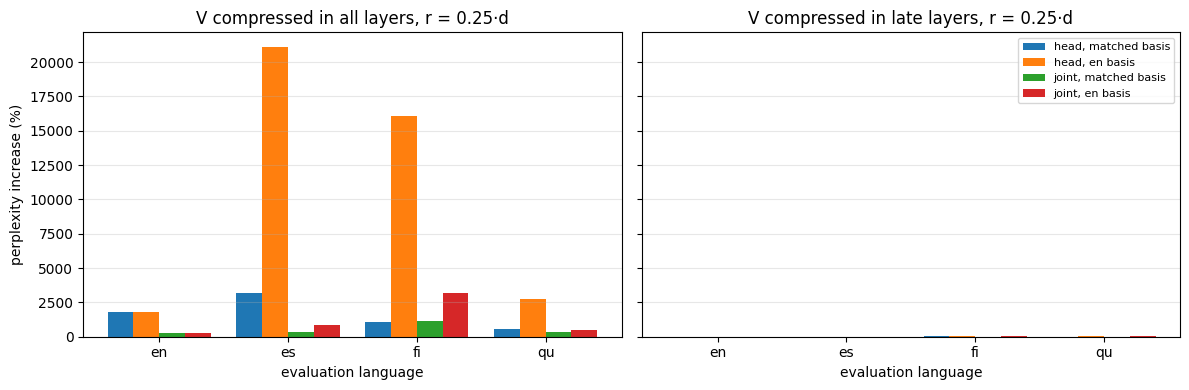

In [11]:
src0 = LANGS[0]
f_plot = 0.25
lsets = list(LAYER_SETS)
fig, axes = plt.subplots(1, len(lsets), figsize=(6 * len(lsets), 4), squeeze=False, sharey=True)
w = 0.2
for ax, lset in zip(axes[0], lsets):
    x = np.arange(len(LANGS))
    for k, (scope, src) in enumerate([("head", "matched"), ("head", src0), ("joint", "matched"), ("joint", src0)]):
        vals = []
        for tgt in LANGS:
            s = tgt if src == "matched" else src
            q = res[(res.kind == "V") & (res.layers == lset) & (res.rank_frac == f_plot)
                    & (res.scope == scope) & (res.target == tgt) & (res.source == s)]
            vals.append(q.ppl_increase_pct.iloc[0])
        ax.bar(x + (k - 1.5) * w, vals, w, label=f"{scope}, {src} basis")
    ax.set_xticks(x, LANGS); ax.set_xlabel("evaluation language")
    ax.set_title(f"V compressed in {lset} layers, r = {f_plot:g}·d"); ax.grid(axis="y", alpha=.3)
axes[0][0].set_ylabel("perplexity increase (%)"); axes[0][-1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "ppl_matched_vs_english.png"), dpi=150); plt.show()

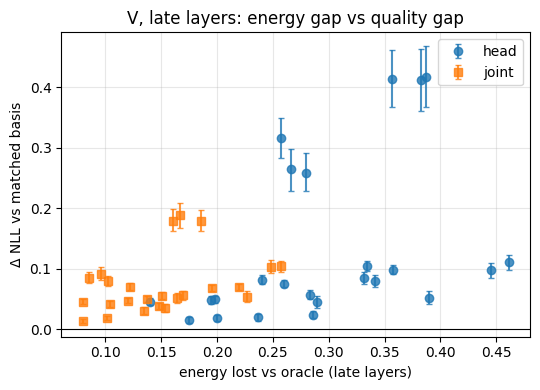

In [12]:
# energy and quality on the same axes: does the energy gap predict the perplexity gap?
e = (energy[(energy.kind == "V")].groupby(["rank_frac", "scope", "source", "target", "band"])
     .efficiency.mean().reset_index())
q = res[(res.kind == "V") & res.source.isin(LANGS) & (res.source != res.target)].copy()
q["band"] = np.where(q.layers == "late", "late", "all")
m = q.merge(e[e.band == "late"].drop(columns="band"), on=["rank_frac", "scope", "source", "target"])
m = m[m.layers == "late"]
fig, ax = plt.subplots(figsize=(5.5, 4))
for scope, mk in (("head", "o"), ("joint", "s")):
    s = m[m.scope == scope]
    ax.errorbar(1 - s.efficiency, s.delta_nll, yerr=[s.delta_nll - s.ci_low, s.ci_high - s.delta_nll],
                fmt=mk, alpha=.8, label=scope, capsize=2)
ax.axhline(0, color="k", lw=.8)
ax.set_xlabel("energy lost vs oracle (late layers)"); ax.set_ylabel("Δ NLL vs matched basis")
ax.set_title("V, late layers: energy gap vs quality gap"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "energy_vs_quality.png"), dpi=150); plt.show()

## 8. Reading guide

1. **Noise floor first.** In the energy tables, the diagonal (`en → en`, `qu → qu`) is what a
   basis loses on new text of the same language. Compare every off-diagonal value with it.
2. **Then quality.** A foreign basis matters only if its `delta_nll` CI excludes 0.
3. **Expected pattern if Week 1b holds:** significant penalties for `en → fi` and `en → qu`
   on V in late layers, smaller with `joint` scope, and none for K.
4. **If the pattern fails:** energy lost in values is not perplexity lost, and the Week 1b
   result is a spectral curiosity rather than a deployment problem. That is still worth reporting.

Upload `ppl_results.csv`, `energy_heldout.csv` and the PNGs to the same Drive folder as before.